In [46]:
pip install iTransformer optuna pandas numpy scikit-learn torch matplotlib

Note: you may need to restart the kernel to use updated packages.


In [47]:
# Import shared modules
import sys
sys.path.append('.')

from data_loader import load_btc_data, create_hourly_data, create_validation_periods, create_sequences
from model_utils import load_model, make_predictions, prepare_tensor
from backtest_functions import backtest_profit_threshold_with_trades, backtest_profit_threshold, backtest_ts_momentum
from utils import cv_optimize_threshold_parameters, cv_optimize_risk_parameters, cv_optimize_momentum_parameters, plot_trades, save_trades_to_csv, create_trades_dataframe

# Force reload modules
import importlib
import backtest_functions
importlib.reload(backtest_functions)
import data_loader
importlib.reload(data_loader)
import utils
importlib.reload(utils)
from data_loader import create_validation_periods
from utils import cv_optimize_threshold_parameters

# Explicitly reload the optimization function
importlib.reload(utils)
from utils import cv_optimize_threshold_parameters

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [48]:
path = "./data/"

In [49]:
# Load price-only data
print("Loading BTC data...")
df = load_btc_data(path)

print("Creating hourly price data...")
features = ['price_change_1h', 'close', 'usd_volume_buy', 'usd_volume_sell']
df_hourly = create_hourly_data(df, features)

print(f"Data shape: {df_hourly.shape}")
df_hourly.head()

Loading BTC data...
Creating hourly price data...
Data shape: (71857, 4)


,price_change_1h,close,usd_volume_buy,usd_volume_sell
datetime,,,,
2017-08-17 05:00:00,6.49,4315.32,92608.279728,100304.823567
2017-08-17 06:00:00,9.03,4324.35,20795.317224,31282.312668
2017-08-17 07:00:00,25.64,4349.99,11291.347015,19241.058300
2017-08-17 08:00:00,10.70,4360.69,3552.746819,4239.503588
2017-08-17 09:00:00,83.31,4444.00,44995.378159,47219.355945


In [50]:
# Create validation periods
train_df, val_df_period1, val_df_period2 = create_validation_periods(df_hourly)

print(f"Training data: {len(train_df)} samples")
print(f"Period 1 validation: {len(val_df_period1)} samples")
print(f"Period 2 validation: {len(val_df_period2)} samples")

# Create sequences
seq_length = 24*7  # 7 days
X_val_period1, y_val_period1 = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=True)
X_val_period2, y_val_period2 = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=True)

print(f"Period 1 - X shape: {X_val_period1.shape}, y shape: {y_val_period1.shape}")

# Use period 1 for initial testing
X_val, y_val = X_val_period1, y_val_period1

Training data: 59388 samples
Period 1 validation: 4392 samples
Period 2 validation: 4344 samples
Period 1 - X shape: (4224, 168, 4), y shape: (4224,)


In [51]:
# Clear any cached variables
try:
    del model, device, X_val_tensor, val_pred_1h_change
except NameError:
    pass

# Load price-only model
model_path = 'itransformer_model_params_dim-64_depth-2_heads-16_lr-0.009526087003989034.pth'
model, device = load_model(model_path, num_variates=4, lookback_len=24*7, dim=64, depth=2, heads=16, dim_head=32)

print(f"Model loaded, num_variates: {model.num_variates}, lookback_len: {model.lookback_len}")

# Prepare data
print(f"X_val shape: {X_val.shape}")
X_val_tensor = prepare_tensor(X_val, device)
print(f"X_val_tensor shape: {X_val_tensor.shape}")

# Make predictions
print("Making predictions...")
val_pred_1h_change = make_predictions(model, X_val_tensor, device, df_hourly.columns.get_loc('price_change_1h'))

# Get close prices for backtesting
close_price = val_df_period1['close'][seq_length:].values

print(f"Predictions shape: {val_pred_1h_change.shape}")
print(f"Close price shape: {close_price.shape}")

Model loaded, num_variates: 4, lookback_len: 168
X_val shape: (4224, 168, 4)
X_val_tensor shape: torch.Size([4224, 168, 4])
Making predictions...
Predictions shape: (4224,)
Close price shape: (4224,)


Performing CV optimization on training data...
CV optimizing threshold parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10...


[I 2025-12-09 22:27:16,642] A new study created in memory with name: no-name-b49c2eff-2b77-4a66-b1a5-03bc48f2a519
[I 2025-12-09 22:27:16,707] Trial 0 finished with value: -2.6793908958860984 and parameters: {'threshold': 1.577258689994283, 'hold_hours': 161}. Best is trial 0 with value: -2.6793908958860984.
[I 2025-12-09 22:27:16,714] Trial 1 finished with value: -3.8579846314113984 and parameters: {'threshold': 0.9429593124386068, 'hold_hours': 81}. Best is trial 0 with value: -2.6793908958860984.
[I 2025-12-09 22:27:16,730] Trial 3 finished with value: -2.8421150360215863 and parameters: {'threshold': 1.6092608530533277, 'hold_hours': 92}. Best is trial 0 with value: -2.6793908958860984.
[I 2025-12-09 22:27:16,747] Trial 2 finished with value: -3.9426828922840578 and parameters: {'threshold': 0.9187247742859248, 'hold_hours': 93}. Best is trial 0 with value: -2.6793908958860984.
[I 2025-12-09 22:27:16,753] Trial 5 finished with value: -5.1607417434603695 and parameters: {'threshold':

Fold 1 - Best threshold: 1.87%, Hold hours: 139, Sharpe: -2.31
Processing CV fold 2/10...


[I 2025-12-09 22:27:21,465] A new study created in memory with name: no-name-d68badbd-014a-4bb6-9c0a-24b0b718fa1b
[I 2025-12-09 22:27:21,495] Trial 0 finished with value: -2.3997474331188244 and parameters: {'threshold': 1.7899324151041691, 'hold_hours': 83}. Best is trial 0 with value: -2.3997474331188244.
[I 2025-12-09 22:27:21,501] Trial 1 finished with value: -2.961223300423278 and parameters: {'threshold': 0.8676390192622601, 'hold_hours': 45}. Best is trial 0 with value: -2.3997474331188244.
[I 2025-12-09 22:27:21,530] Trial 2 finished with value: -3.4203302841986085 and parameters: {'threshold': 0.6826667690691004, 'hold_hours': 145}. Best is trial 0 with value: -2.3997474331188244.
[I 2025-12-09 22:27:21,540] Trial 3 finished with value: -3.3595675357973644 and parameters: {'threshold': 1.532136785103844, 'hold_hours': 30}. Best is trial 0 with value: -2.3997474331188244.
[I 2025-12-09 22:27:21,540] Trial 4 finished with value: -1.2700869718714047 and parameters: {'threshold': 

Fold 2 - Best threshold: 1.97%, Hold hours: 70, Sharpe: -0.14
Processing CV fold 3/10...


[I 2025-12-09 22:27:26,050] A new study created in memory with name: no-name-2c27067f-6227-41ca-b733-3dd2b8815100
[I 2025-12-09 22:27:26,066] Trial 0 finished with value: -3.927961029872925 and parameters: {'threshold': 0.42623091411744807, 'hold_hours': 50}. Best is trial 0 with value: -3.927961029872925.
[I 2025-12-09 22:27:26,124] Trial 3 finished with value: -2.9182593173294507 and parameters: {'threshold': 0.22358181195655552, 'hold_hours': 41}. Best is trial 3 with value: -2.9182593173294507.
[I 2025-12-09 22:27:26,128] Trial 1 finished with value: -2.4950608192882924 and parameters: {'threshold': 1.592369734019531, 'hold_hours': 98}. Best is trial 1 with value: -2.4950608192882924.
[I 2025-12-09 22:27:26,128] Trial 4 finished with value: -2.857044927787602 and parameters: {'threshold': 0.2481449664251712, 'hold_hours': 37}. Best is trial 1 with value: -2.4950608192882924.
[I 2025-12-09 22:27:26,128] Trial 2 finished with value: -2.3955848954484704 and parameters: {'threshold': 1

... (11 outputs left out)

[I 2025-12-09 22:27:54,055] A new study created in memory with name: no-name-031adf75-c320-4065-94fb-21cda7253770
[I 2025-12-09 22:27:54,072] Trial 0 finished with value: -0.34242623032233543 and parameters: {'threshold': 0.4207180564168096, 'hold_hours': 135}. Best is trial 0 with value: -0.34242623032233543.
[I 2025-12-09 22:27:54,097] Trial 1 finished with value: -0.010973219457934046 and parameters: {'threshold': 0.6676724594524628, 'hold_hours': 78}. Best is trial 1 with value: -0.010973219457934046.
[I 2025-12-09 22:27:54,107] Trial 2 finished with value: 0.22324604851300492 and parameters: {'threshold': 1.7143606593654628, 'hold_hours': 140}. Best is trial 2 with value: 0.22324604851300492.
[I 2025-12-09 22:27:54,117] Trial 3 finished with value: -0.432854743371361 and parameters: {'threshold': 1.0571657901503322, 'hold_hours': 119}. Best is trial 2 with value: 0.22324604851300492.
[I 2025-12-09 22:27:54,152] Trial 5 finished with value: -0.34132874994881135 and parameters: {'th

Fold 9 - Best threshold: 0.52%, Hold hours: 131, Sharpe: 1.78
Processing CV fold 10/10...


[I 2025-12-09 22:27:58,841] A new study created in memory with name: no-name-869c6dd3-7aa9-4cff-b794-48db6a6af2f7
[I 2025-12-09 22:27:58,886] Trial 0 finished with value: -0.4676651893929338 and parameters: {'threshold': 1.4537376724307056, 'hold_hours': 63}. Best is trial 0 with value: -0.4676651893929338.
[I 2025-12-09 22:27:58,887] Trial 1 finished with value: -0.776375632117937 and parameters: {'threshold': 1.8012275483690954, 'hold_hours': 143}. Best is trial 0 with value: -0.4676651893929338.
[I 2025-12-09 22:27:58,904] Trial 2 finished with value: -0.4795871618455812 and parameters: {'threshold': 1.851269736227384, 'hold_hours': 41}. Best is trial 0 with value: -0.4676651893929338.
[I 2025-12-09 22:27:58,910] Trial 3 finished with value: -0.39361176386932945 and parameters: {'threshold': 1.4998837428347211, 'hold_hours': 93}. Best is trial 3 with value: -0.39361176386932945.
[I 2025-12-09 22:27:58,919] Trial 4 finished with value: 0.09125163346539188 and parameters: {'threshold'

Fold 10 - Best threshold: 1.92%, Hold hours: 136, Sharpe: 1.55
CV Best threshold: 1.42%, Hold hours: 88, Average Sharpe ratio: 0.97

Optimized parameters:
Threshold: 1.42%
Hold Hours: 88

BACKTESTING ON TEST DATA

--- Test Period 1 ---
Backtest trades saved to backtest_results/price_only/threshold_backtest_trades-1.csv (2 trades)


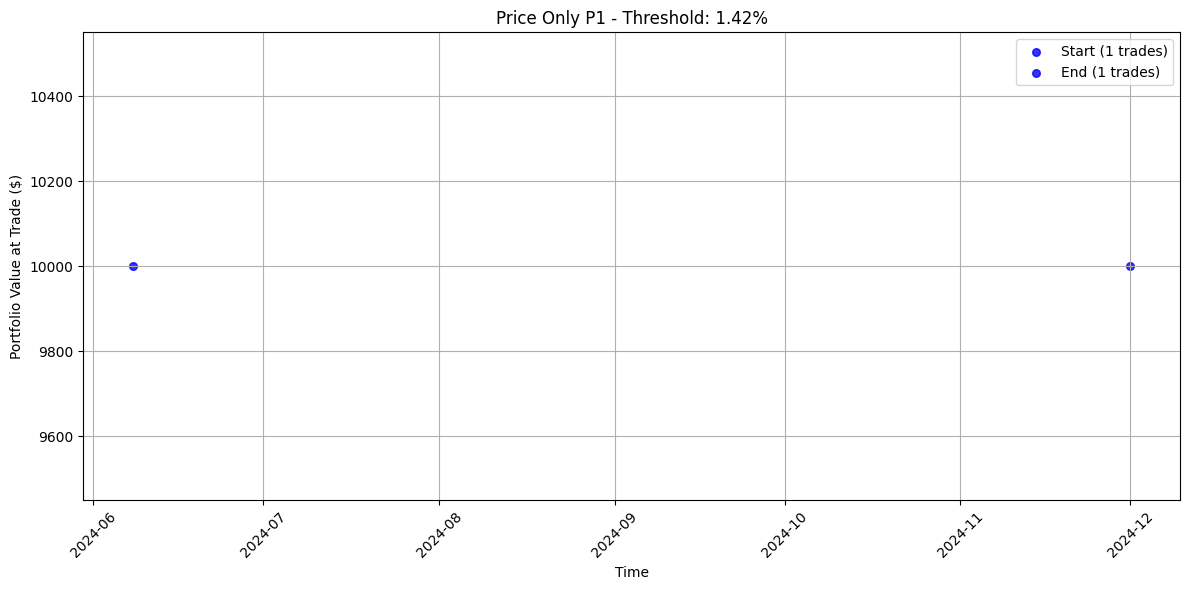


--- Test Period 2 ---
Backtest trades saved to backtest_results/price_only/threshold_backtest_trades-2.csv (8 trades)


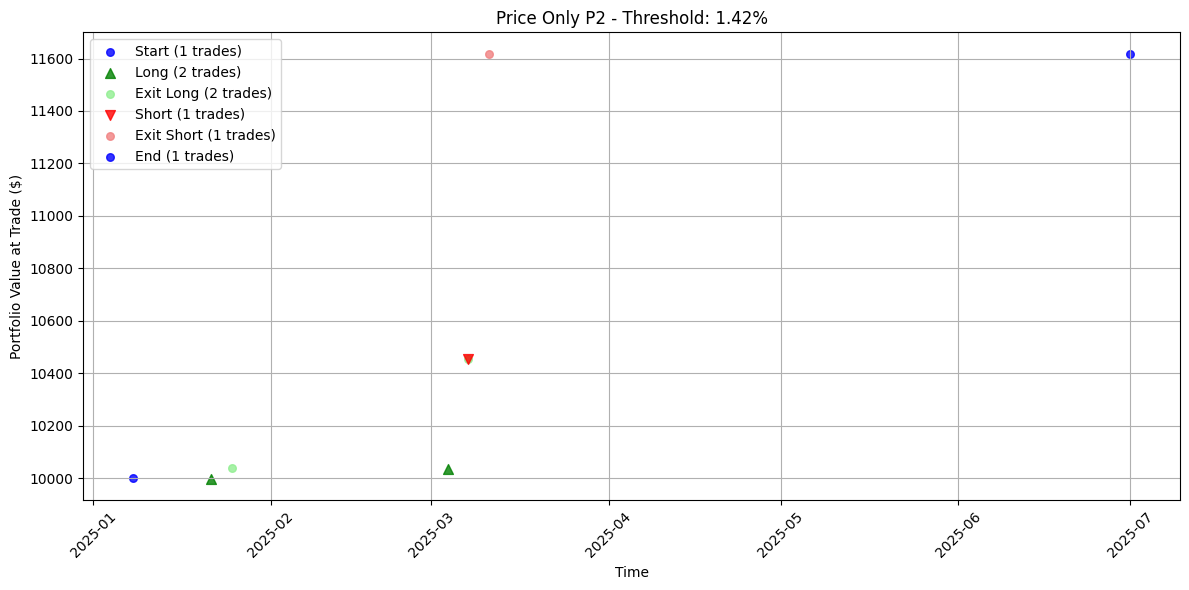

In [52]:
# CV Optimization and Backtesting on Test Data
initial_capital = 10000
fixed_transaction_cost_pct = 0.0275
seq_length = 24*7  # 7 days

print("Performing CV optimization on training data...")

# CV optimize threshold parameters
print("CV optimizing threshold parameters...")
# Load CPU model for CV
cv_model, cv_device = load_model(model_path, num_variates=4, lookback_len=24*7, dim=64, depth=2, heads=16, device='cpu')
best_threshold, best_hold_hours = cv_optimize_threshold_parameters(
    train_df, cv_model, cv_device, seq_length, 'price_change_1h', initial_capital, fixed_transaction_cost_pct, include_target=True
)

print(f"\nOptimized parameters:")
print(f"Threshold: {best_threshold:.2f}%")
print(f"Hold Hours: {best_hold_hours}")

# Now backtest on test periods with optimized parameters
print("\n" + "="*50)
print("BACKTESTING ON TEST DATA")
print("="*50)

# Test Period 1 Backtests
print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=True)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Threshold backtest on period 1
importlib.reload(backtest_functions)
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_functions.backtest_profit_threshold_with_trades(
    close_price_p1, test_pred_p1, initial_capital, best_threshold, fixed_transaction_cost_pct, best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p1, "Threshold Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/price_only/threshold_backtest_trades-1.csv')
plot_trades(trades_df, f'Price Only P1 - Threshold: {best_threshold:.2f}%')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=True)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Threshold backtest on period 2
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold_with_trades(
    close_price_p2, test_pred_p2, initial_capital, best_threshold, fixed_transaction_cost_pct, best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p2, "Threshold Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/price_only/threshold_backtest_trades-2.csv')
plot_trades(trades_df, f'Price Only P2 - Threshold: {best_threshold:.2f}%')

CV optimizing risk parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for risk optimization...


[I 2025-12-09 22:28:04,175] A new study created in memory with name: no-name-29a27df0-f495-4e1a-bbd6-f72266bab947
[I 2025-12-09 22:28:04,202] Trial 0 finished with value: -3.077299232784384 and parameters: {'threshold': 1.713936224113157, 'target_risk': 0.6905878466849797, 'hold_hours': 85}. Best is trial 0 with value: -3.077299232784384.
[I 2025-12-09 22:28:04,266] Trial 1 finished with value: -3.6646149381238233 and parameters: {'threshold': 1.5344108540739745, 'target_risk': 2.0940257566626888, 'hold_hours': 31}. Best is trial 0 with value: -3.077299232784384.
[I 2025-12-09 22:28:04,267] Trial 3 finished with value: -4.22613379840822 and parameters: {'threshold': 1.1492360654505225, 'target_risk': 2.203053805788518, 'hold_hours': 15}. Best is trial 0 with value: -3.077299232784384.
[I 2025-12-09 22:28:04,268] Trial 2 finished with value: -3.5972277736517153 and parameters: {'threshold': 1.2459186851911022, 'target_risk': 2.0745913139519634, 'hold_hours': 134}. Best is trial 0 with v

Fold 1 - Best threshold: 1.97%, Risk: 0.41%, Hold hours: 166, Sharpe: -2.12
Processing CV fold 2/10 for risk optimization...


[I 2025-12-09 22:28:17,926] A new study created in memory with name: no-name-d035d719-0990-406d-a7a3-f22e534fe53b
[I 2025-12-09 22:28:17,949] Trial 0 finished with value: -2.9032882491273444 and parameters: {'threshold': 0.6245617724051842, 'target_risk': 0.7012599183259535, 'hold_hours': 65}. Best is trial 0 with value: -2.9032882491273444.
[I 2025-12-09 22:28:17,983] Trial 1 finished with value: -2.1668882837070633 and parameters: {'threshold': 1.114712879586162, 'target_risk': 2.4790680352749166, 'hold_hours': 134}. Best is trial 1 with value: -2.1668882837070633.
[I 2025-12-09 22:28:17,999] Trial 3 finished with value: -2.187358938530309 and parameters: {'threshold': 1.4749405472155868, 'target_risk': 1.9753761429187482, 'hold_hours': 84}. Best is trial 1 with value: -2.1668882837070633.
[I 2025-12-09 22:28:18,000] Trial 2 finished with value: -1.0907299945573878 and parameters: {'threshold': 1.029496581711599, 'target_risk': 0.9418406236671668, 'hold_hours': 25}. Best is trial 2 w

Fold 2 - Best threshold: 2.00%, Risk: 1.03%, Hold hours: 7, Sharpe: 0.11
Processing CV fold 3/10 for risk optimization...


[I 2025-12-09 22:28:29,991] A new study created in memory with name: no-name-de0b064d-6b3a-4346-bbf1-6032cc15081a
[I 2025-12-09 22:28:30,062] Trial 2 finished with value: -0.8816580631390052 and parameters: {'threshold': 0.8721161616452531, 'target_risk': 0.07201526301127771, 'hold_hours': 164}. Best is trial 2 with value: -0.8816580631390052.
[I 2025-12-09 22:28:30,078] Trial 3 finished with value: -1.9469045443523771 and parameters: {'threshold': 0.7561231916561596, 'target_risk': 0.5849247038145935, 'hold_hours': 73}. Best is trial 2 with value: -0.8816580631390052.
[I 2025-12-09 22:28:30,084] Trial 4 finished with value: -2.1654625357698163 and parameters: {'threshold': 0.5250952847329324, 'target_risk': 1.5203312570457808, 'hold_hours': 58}. Best is trial 2 with value: -0.8816580631390052.
[I 2025-12-09 22:28:30,108] Trial 0 finished with value: -0.8690608669695948 and parameters: {'threshold': 1.339701333291251, 'target_risk': 1.0948587871045956, 'hold_hours': 59}. Best is trial 

... (11 outputs left out)

[I 2025-12-09 22:29:47,050] A new study created in memory with name: no-name-ddbebfb9-11ab-477b-b688-42af782ddf90
[I 2025-12-09 22:29:47,071] Trial 0 finished with value: -0.4220685611092727 and parameters: {'threshold': 1.7518104290721301, 'target_risk': 1.1737108941508938, 'hold_hours': 40}. Best is trial 0 with value: -0.4220685611092727.
[I 2025-12-09 22:29:47,119] Trial 3 finished with value: -0.9092429693702551 and parameters: {'threshold': 1.500693574223906, 'target_risk': 2.1405880640260695, 'hold_hours': 70}. Best is trial 0 with value: -0.4220685611092727.
[I 2025-12-09 22:29:47,131] Trial 4 finished with value: 0.18630126556207816 and parameters: {'threshold': 0.4853894627831534, 'target_risk': 0.8542085145474066, 'hold_hours': 122}. Best is trial 4 with value: 0.18630126556207816.
[I 2025-12-09 22:29:47,143] Trial 1 finished with value: -0.18671976962732426 and parameters: {'threshold': 0.4025492170951835, 'target_risk': 1.517336221852361, 'hold_hours': 143}. Best is trial 

Fold 9 - Best threshold: 0.52%, Risk: 1.63%, Hold hours: 136, Sharpe: 1.92
Processing CV fold 10/10 for risk optimization...


[I 2025-12-09 22:30:01,140] A new study created in memory with name: no-name-169df11a-3add-494b-96ec-a9548eff5c27
[I 2025-12-09 22:30:01,190] Trial 2 finished with value: -2.2957205430115035 and parameters: {'threshold': 1.6227704601809259, 'target_risk': 2.2724598645845475, 'hold_hours': 39}. Best is trial 2 with value: -2.2957205430115035.
[I 2025-12-09 22:30:01,191] Trial 0 finished with value: -1.0768204208013434 and parameters: {'threshold': 0.2677384341108382, 'target_risk': 0.7662611916194216, 'hold_hours': 137}. Best is trial 0 with value: -1.0768204208013434.
[I 2025-12-09 22:30:01,230] Trial 1 finished with value: -1.5736708292386363 and parameters: {'threshold': 0.11328415487185067, 'target_risk': 1.0626293672905156, 'hold_hours': 168}. Best is trial 0 with value: -1.0768204208013434.
[I 2025-12-09 22:30:01,240] Trial 4 finished with value: 1.180779117052245 and parameters: {'threshold': 1.3291860388053576, 'target_risk': 0.7342866457830903, 'hold_hours': 130}. Best is trial

Fold 10 - Best threshold: 1.34%, Risk: 2.15%, Hold hours: 96, Sharpe: 1.53
CV Optimal threshold: 1.36%, Risk: 1.23%, Hold hours: 80, Average Sharpe: 1.09

Optimized parameters:
Threshold: 1.36%
Target Risk: 1.23%
Hold Hours: 80

--- Test Period 1 ---
Backtest trades saved to backtest_results/price_only/risk_based_backtest_trades-1.csv (2 trades)


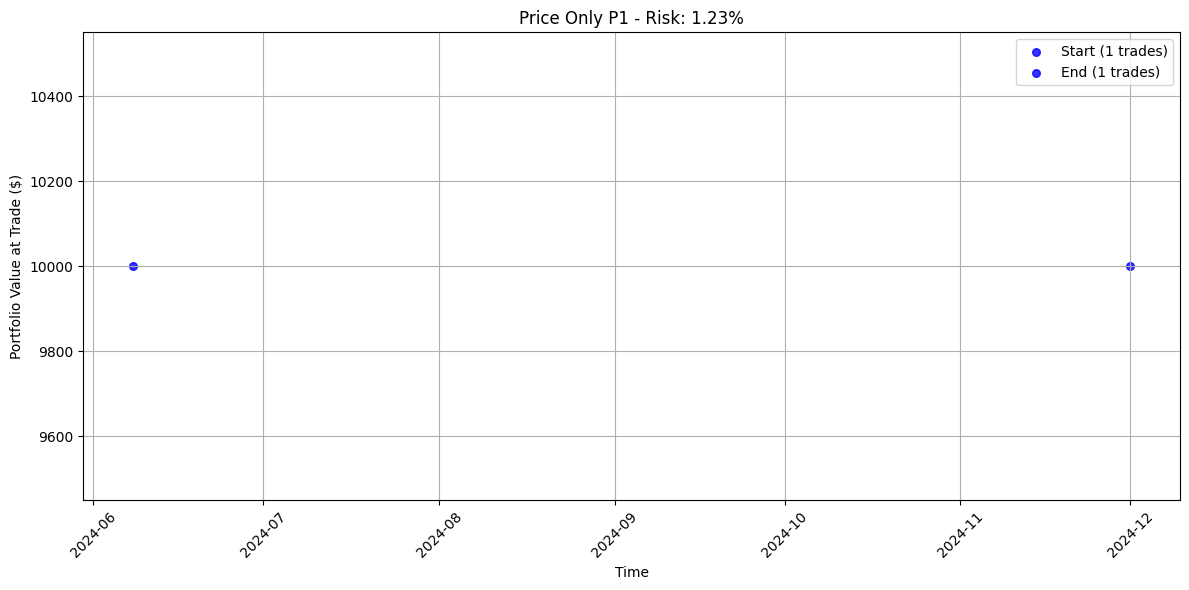


--- Test Period 2 ---
Backtest trades saved to backtest_results/price_only/risk_based_backtest_trades-2.csv (12 trades)


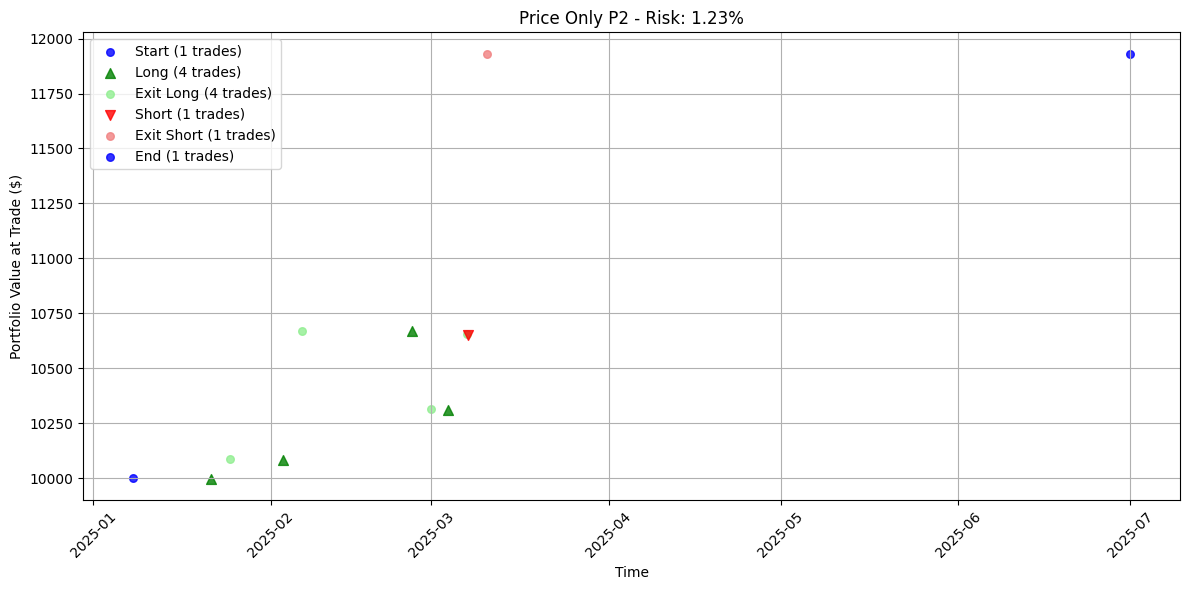

In [53]:
# CV optimize risk parameters
print("CV optimizing risk parameters...")
best_threshold, best_target_risk, best_hold_hours = cv_optimize_risk_parameters(
    train_df, cv_model, cv_device, seq_length, 'price_change_1h', initial_capital, fixed_transaction_cost_pct, include_target=True
)

print(f"\nOptimized parameters:")
print(f"Threshold: {best_threshold:.2f}%")
print(f"Target Risk: {best_target_risk:.2f}%")
print(f"Hold Hours: {best_hold_hours}")

print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=True)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Risk-based backtest on period 1
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold(
    close_price_p1, test_pred_p1, initial_capital, best_threshold, target_risk_per_trade=best_target_risk, transaction_cost_pct=fixed_transaction_cost_pct, hold_hours=best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p1, "Risk-Based Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/price_only/risk_based_backtest_trades-1.csv')
plot_trades(trades_df, f'Price Only P1 - Risk: {best_target_risk:.2f}%')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=True)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Risk-based backtest on period 2
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold(
    close_price_p2, test_pred_p2, initial_capital, best_threshold, target_risk_per_trade=best_target_risk, transaction_cost_pct=fixed_transaction_cost_pct, hold_hours=best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p2, "Risk-Based Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/price_only/risk_based_backtest_trades-2.csv')
plot_trades(trades_df, f'Price Only P2 - Risk: {best_target_risk:.2f}%')

CV optimizing momentum parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for momentum optimization...


[I 2025-12-09 22:30:13,585] A new study created in memory with name: no-name-55fd7d8e-3a53-4a97-8dab-51ffacd590a4
[I 2025-12-09 22:30:13,630] Trial 0 finished with value: 0.37866761076233674 and parameters: {'lookback': 93, 'hold_hours': 71, 'signal_thresh': 0.026844674236346247, 'target_risk': 1.7000494991382267}. Best is trial 0 with value: 0.37866761076233674.
[I 2025-12-09 22:30:13,683] Trial 4 finished with value: -4.047522146121693 and parameters: {'lookback': 3, 'hold_hours': 135, 'signal_thresh': 1.1578645886815992, 'target_risk': 2.0369482694025245}. Best is trial 0 with value: 0.37866761076233674.
[I 2025-12-09 22:30:13,694] Trial 2 finished with value: 0.4869757458958286 and parameters: {'lookback': 17, 'hold_hours': 73, 'signal_thresh': 1.3157530368384092, 'target_risk': 1.6943377922842973}. Best is trial 2 with value: 0.4869757458958286.
[I 2025-12-09 22:30:13,721] Trial 6 finished with value: 0.47645452337963706 and parameters: {'lookback': 48, 'hold_hours': 67, 'signal_t

Fold 1 - Best lookback: 22, hold_hours: 77, signal_thresh: 1.872, target_risk: 1.691, Sharpe: 2.74
Processing CV fold 2/10 for momentum optimization...


[I 2025-12-09 22:30:42,905] A new study created in memory with name: no-name-dee82b1d-1301-4886-9236-d9119c180bcf
[I 2025-12-09 22:30:42,927] Trial 0 finished with value: 0.7793540730867361 and parameters: {'lookback': 22, 'hold_hours': 105, 'signal_thresh': 1.7589914158759201, 'target_risk': 0.006628028179591905}. Best is trial 0 with value: 0.7793540730867361.
[I 2025-12-09 22:30:42,985] Trial 4 finished with value: 0.5866813065216219 and parameters: {'lookback': 24, 'hold_hours': 16, 'signal_thresh': 0.8646026056487084, 'target_risk': 2.2962114460821494}. Best is trial 0 with value: 0.7793540730867361.
[I 2025-12-09 22:30:42,986] Trial 2 finished with value: 0.8846547382557521 and parameters: {'lookback': 151, 'hold_hours': 34, 'signal_thresh': 1.3162532616945977, 'target_risk': 1.775560890322402}. Best is trial 2 with value: 0.8846547382557521.
[I 2025-12-09 22:30:42,987] Trial 1 finished with value: 0.833573352737983 and parameters: {'lookback': 146, 'hold_hours': 51, 'signal_thre

Fold 2 - Best lookback: 87, hold_hours: 112, signal_thresh: 1.288, target_risk: 1.756, Sharpe: 2.34
Processing CV fold 3/10 for momentum optimization...


[I 2025-12-09 22:31:11,235] A new study created in memory with name: no-name-5cc32e04-8f00-47d9-8fa1-db9136e77243
[I 2025-12-09 22:31:11,255] Trial 0 finished with value: 0.43278737137599504 and parameters: {'lookback': 133, 'hold_hours': 77, 'signal_thresh': 1.027072358198044, 'target_risk': 2.2522362573862487}. Best is trial 0 with value: 0.43278737137599504.
[I 2025-12-09 22:31:11,323] Trial 3 finished with value: -0.09654020782765904 and parameters: {'lookback': 112, 'hold_hours': 60, 'signal_thresh': 0.17681938193240151, 'target_risk': 1.3108796465609247}. Best is trial 0 with value: 0.43278737137599504.
[I 2025-12-09 22:31:11,324] Trial 2 finished with value: -0.43603009383241126 and parameters: {'lookback': 5, 'hold_hours': 165, 'signal_thresh': 1.37601002301859, 'target_risk': 1.3643260666713353}. Best is trial 0 with value: 0.43278737137599504.
[I 2025-12-09 22:31:11,324] Trial 4 finished with value: 1.271733557396633 and parameters: {'lookback': 118, 'hold_hours': 11, 'signal

... (11 outputs left out)

[I 2025-12-09 22:34:06,309] A new study created in memory with name: no-name-3fbed6b0-643f-4254-b77f-8b88b33a5942
[I 2025-12-09 22:34:06,349] Trial 1 finished with value: -1.2146783284365896 and parameters: {'lookback': 115, 'hold_hours': 152, 'signal_thresh': 0.20973095621842078, 'target_risk': 1.1036955975317533}. Best is trial 1 with value: -1.2146783284365896.
[I 2025-12-09 22:34:06,377] Trial 0 finished with value: -0.45239524328204256 and parameters: {'lookback': 42, 'hold_hours': 79, 'signal_thresh': 1.5527085898884654, 'target_risk': 1.1018473573816268}. Best is trial 0 with value: -0.45239524328204256.
[I 2025-12-09 22:34:06,391] Trial 5 finished with value: -0.42162431223607166 and parameters: {'lookback': 92, 'hold_hours': 160, 'signal_thresh': 1.2731491815181786, 'target_risk': 0.6401344364869388}. Best is trial 5 with value: -0.42162431223607166.
[I 2025-12-09 22:34:06,410] Trial 3 finished with value: -0.696428477370402 and parameters: {'lookback': 144, 'hold_hours': 144,

Fold 9 - Best lookback: 13, hold_hours: 98, signal_thresh: 0.908, target_risk: 0.133, Sharpe: 3.09
Processing CV fold 10/10 for momentum optimization...


[I 2025-12-09 22:34:35,989] A new study created in memory with name: no-name-6cdc1364-8e3a-48d5-99f5-b9aa259b80c7
[I 2025-12-09 22:34:36,038] Trial 1 finished with value: 1.4361349763889795 and parameters: {'lookback': 96, 'hold_hours': 124, 'signal_thresh': 1.6999281586051835, 'target_risk': 0.2571617689532152}. Best is trial 1 with value: 1.4361349763889795.
[I 2025-12-09 22:34:36,052] Trial 3 finished with value: 1.0792419676922795 and parameters: {'lookback': 111, 'hold_hours': 68, 'signal_thresh': 1.6122623923775294, 'target_risk': 0.5539181165384044}. Best is trial 1 with value: 1.4361349763889795.
[I 2025-12-09 22:34:36,069] Trial 2 finished with value: 0.050036037772096184 and parameters: {'lookback': 32, 'hold_hours': 8, 'signal_thresh': 0.611155414014829, 'target_risk': 1.8991250518470086}. Best is trial 1 with value: 1.4361349763889795.
[I 2025-12-09 22:34:36,073] Trial 4 finished with value: -0.28227069596696336 and parameters: {'lookback': 20, 'hold_hours': 52, 'signal_thr

Fold 10 - Best lookback: 89, hold_hours: 86, signal_thresh: 1.915, target_risk: 0.815, Sharpe: 3.21
CV Optimal lookback: 67, hold_hours: 79, signal_thresh: 1.252, target_risk: 0.685, Average Sharpe: 2.79

Optimized parameters:
Lookback: 67
Hold Hours: 79
Signal Threshold: 1.252
Target Risk: 0.685

--- Test Period 1 ---
Backtest trades saved to backtest_results/price_only/momentum_backtest_trades-1.csv (173 trades)


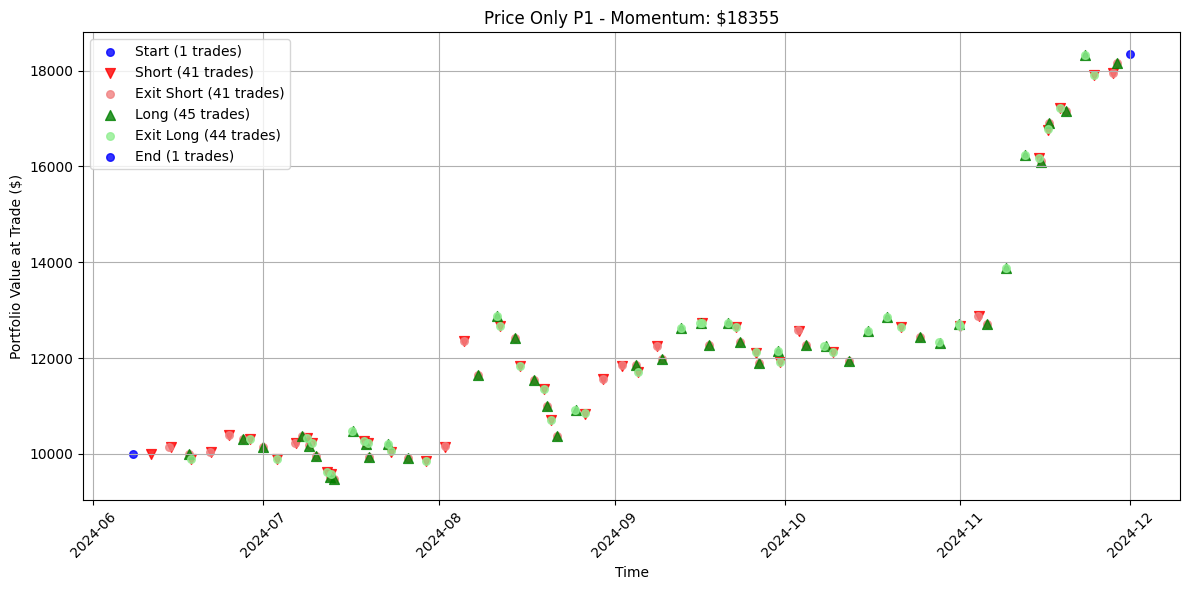


--- Test Period 2 ---
Backtest trades saved to backtest_results/price_only/momentum_backtest_trades-2.csv (176 trades)


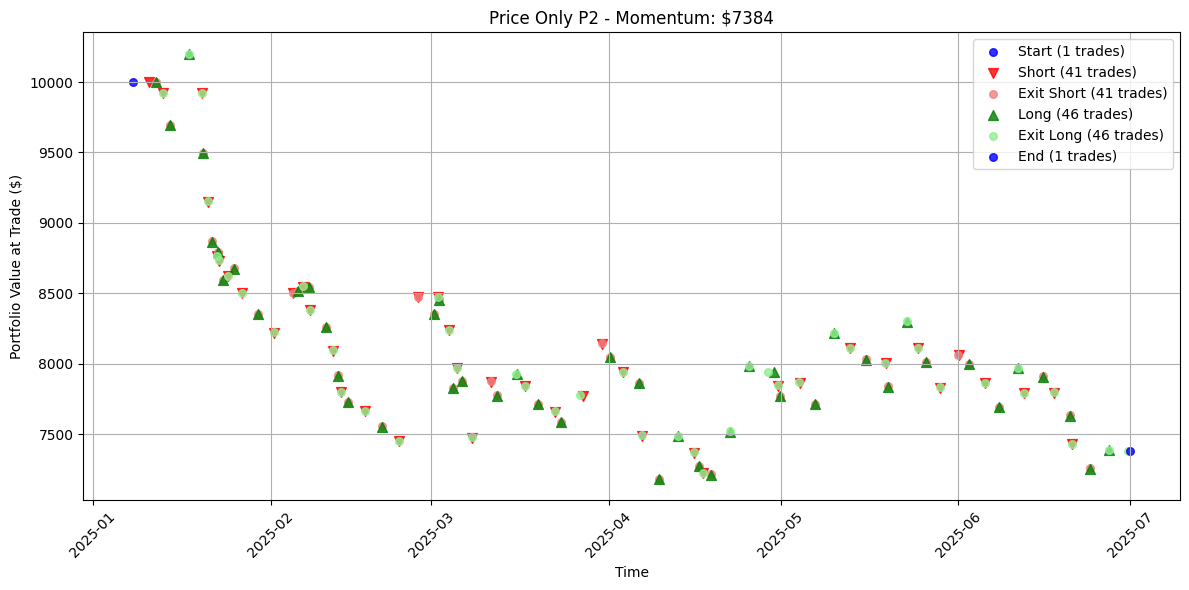

In [54]:
# CV optimize momentum parameters
print("CV optimizing momentum parameters...")
best_lookback, best_hold_hours, best_signal_thresh, best_target_risk = cv_optimize_momentum_parameters(
    train_df, cv_model, seq_length, 'price_change_1h', fixed_transaction_cost_pct, include_target=True
)

print(f"\nOptimized parameters:")
print(f"Lookback: {best_lookback}")
print(f"Hold Hours: {best_hold_hours}")
print(f"Signal Threshold: {best_signal_thresh:.3f}")
print(f"Target Risk: {best_target_risk:.3f}")

print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=True)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Momentum backtest on period 1
final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p1,
    predicted_changes=test_pred_p1,
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    target_risk_per_trade=best_target_risk,
    threshold=best_signal_thresh,
    initial_capital=10000,
    transaction_cost_pct=fixed_transaction_cost_pct)
trades_df = create_trades_dataframe(trade_times_opt, trade_values_opt, trade_types_opt, plot_index_p1, "Momentum Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/price_only/momentum_backtest_trades-1.csv')
plot_trades(trades_df, f'Price Only P1 - Momentum: ${final_capital_optimal:.0f}')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=True)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Momentum backtest on period 2
final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p2,
    predicted_changes=test_pred_p2,
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    target_risk_per_trade=best_target_risk,
    threshold=best_signal_thresh,
    initial_capital=10000,
    transaction_cost_pct=fixed_transaction_cost_pct)
trades_df = create_trades_dataframe(trade_times_opt, trade_values_opt, trade_types_opt, plot_index_p2, "Momentum Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/price_only/momentum_backtest_trades-2.csv')
plot_trades(trades_df, f'Price Only P2 - Momentum: ${final_capital_optimal:.0f}')